<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C21_Notebook-25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

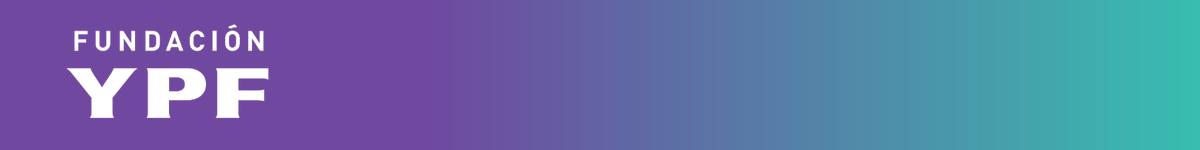

# Fundación YPF - Data Science

## Notebook 25: Clustering con DBSCAN

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: los límites de K-Means
* **Parte 2:** DBSCAN: puntos core, border y noise
* **Parte 3:** Efecto de los parámetros epsilon y min_samples
* **Parte 4:** DBSCAN sobre datos reales: clientes de un centro comercial
* **Parte 5:** K-Means vs DBSCAN
* **Parte 6:** Ejercicio para las salas de Zoom

## Parte 0: Preparación del entorno

En las clases anteriores trabajamos con **K-Means**, que agrupa alrededor de centroides. Hoy vemos **DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*), un algoritmo que define los clusters por **densidad de puntos**. Esto le permite:

* encontrar clusters de **cualquier forma**,
* **no necesitar que le indiquemos el número de clusters**,
* marcar como **ruido** los puntos que no pertenecen a ningún grupo.

**Datasets:**

* `clientes_mall.csv`: 200 clientes de un centro comercial (el mismo de la Notebook 23). Lo usamos en la parte guiada.
* `StudentsPerformance.csv`: puntajes de 1000 estudiantes en tres exámenes. Lo usamos en el ejercicio de las salas.

En las primeras partes además generamos datos sintéticos con scikit-learn, que no necesitan archivo.

Antes de ejecutar, subí los archivos `clientes_mall.csv` y `StudentsPerformance.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import make_moons, make_circles

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## Parte 1: Repaso: los límites de K-Means

K-Means arma regiones compactas alrededor de un centroide. Cuando los grupos tienen otra forma (por ejemplo, una media luna o un anillo), falla. Comparamos los dos algoritmos sobre dos conjuntos de datos sintéticos.

In [ ]:
X_lunas, _ = make_moons(n_samples=400, noise=0.06, random_state=RANDOM_STATE)
X_anillos, _ = make_circles(n_samples=400, factor=0.4, noise=0.05, random_state=RANDOM_STATE)

conjuntos = {"Lunas": (X_lunas, 0.2), "Anillos": (X_anillos, 0.2)}

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for fila, (nombre, (X_s, eps)) in enumerate(conjuntos.items()):
    etiq_km = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_s)
    etiq_db = DBSCAN(eps=eps, min_samples=5).fit_predict(X_s)
    ax[fila, 0].scatter(X_s[:, 0], X_s[:, 1], c=etiq_km, cmap="tab10", alpha=0.7)
    ax[fila, 0].set_title(f"{nombre}: K-Means (k = 2)")
    ax[fila, 1].scatter(X_s[:, 0], X_s[:, 1], c=etiq_db, cmap="tab10", alpha=0.7)
    ax[fila, 1].set_title(f"{nombre}: DBSCAN (epsilon = {eps}, min_samples = 5)")
plt.tight_layout()
plt.show()

K-Means corta las figuras por la mitad. DBSCAN recupera cada grupo porque **sigue la continuidad de los puntos**: dos puntos pertenecen al mismo cluster si se puede ir de uno a otro saltando por zonas densas.

## Parte 2: DBSCAN: puntos core, border y noise

DBSCAN tiene **dos parámetros**:

* **epsilon** (`eps`): el radio que define la **vecindad** de un punto.
* **minPoints** (`min_samples` en scikit-learn): la cantidad mínima de puntos que tiene que haber en esa vecindad para que el punto se considere denso. En scikit-learn el conteo **incluye al propio punto**.

Con eso, cada punto cae en una de tres categorías:

* **Core:** tiene al menos `min_samples` puntos en su vecindad. Es el corazón de un cluster.
* **Border:** no es core, pero está en la vecindad de un punto core. Pertenece al cluster, pero en su borde.
* **Noise:** no es core ni está en la vecindad de ninguno. No pertenece a ningún cluster y scikit-learn le asigna la etiqueta **-1**.

El algoritmo recorre los puntos, y cada vez que encuentra un core arma un cluster y lo va expandiendo con todos los puntos que alcanza desde otros cores. Lo vemos en un ejemplo: lunas con algunos puntos de ruido agregados a propósito.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
X_base, _ = make_moons(n_samples=300, noise=0.07, random_state=RANDOM_STATE)
X_ruido = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(15, 2))
X_demo = np.vstack([X_base, X_ruido])

db = DBSCAN(eps=0.2, min_samples=5).fit(X_demo)

# Clasificamos cada punto en core, border o noise
tipo = np.full(len(X_demo), "border", dtype=object)
tipo[db.core_sample_indices_] = "core"
tipo[db.labels_ == -1] = "noise"

print("Clusters encontrados:", len(set(db.labels_)) - (1 if -1 in db.labels_ else 0))
print(pd.Series(tipo).value_counts().to_string())

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
estilos = {"core": ("o", 40, 0.8), "border": ("s", 40, 0.9), "noise": ("x", 70, 1.0)}
colores = {-1: "black", 0: "#7030A0", 1: "#30BEAA"}

for t, (marcador, tam, alfa) in estilos.items():
    for etiqueta in sorted(set(db.labels_[tipo == t])):
        mask = (tipo == t) & (db.labels_ == etiqueta)
        ax.scatter(X_demo[mask, 0], X_demo[mask, 1], marker=marcador, s=tam, alpha=alfa,
                   color=colores[etiqueta], label=f"{t}" if etiqueta != 1 else None)

ax.set_title("Puntos core (círculos), border (cuadrados) y noise (cruces)")
ax.legend()
plt.tight_layout()
plt.show()

Los círculos forman el interior de cada media luna, los cuadrados aparecen en los bordes y las cruces negras son los puntos aislados que DBSCAN descartó como **ruido**. En K-Means, en cambio, **todo punto termina asignado a algún cluster**, aunque sea un outlier.

## Parte 3: Efecto de los parámetros epsilon y min_samples

DBSCAN es sensible a sus parámetros. Veamos qué pasa con el mismo conjunto de datos al variar `eps`, con `min_samples` fijo.

In [ ]:
valores_eps = [0.05, 0.1, 0.2, 0.5]

fig, ax = plt.subplots(1, 4, figsize=(18, 4.2), sharex=True, sharey=True)
for a, eps in zip(ax, valores_eps):
    etiquetas = DBSCAN(eps=eps, min_samples=5).fit_predict(X_demo)
    n_clusters = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    a.scatter(X_demo[:, 0], X_demo[:, 1], c=etiquetas, cmap="tab10", alpha=0.7, s=25)
    a.set_title(f"eps = {eps}: {n_clusters} clusters, {(etiquetas == -1).sum()} ruido")
plt.tight_layout()
plt.show()

* **Epsilon muy chico:** casi ningún punto llega a tener vecinos suficientes. Hay muchos clusters diminutos y mucho ruido.
* **Epsilon adecuado:** los dos grupos aparecen y el ruido queda limitado a los puntos realmente aislados.
* **Epsilon muy grande:** las vecindades se solapan y todo se junta en un solo cluster.

`min_samples` actúa en el mismo sentido: un valor más alto exige más densidad, así que aparece más ruido y los clusters chicos desaparecen.

In [ ]:
filas = []
for eps in [0.1, 0.15, 0.2, 0.3]:
    for ms in [3, 5, 10, 20]:
        etiquetas = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_demo)
        filas.append({"eps": eps, "min_samples": ms,
                      "clusters": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
                      "ruido": int((etiquetas == -1).sum())})

pd.DataFrame(filas).pivot(index="eps", columns="min_samples", values=["clusters", "ruido"])

## Parte 4: DBSCAN sobre datos reales: clientes de un centro comercial

Volvemos a los clientes del centro comercial de la Notebook 23. Agrupamos por **ingreso anual** y **puntaje de gasto**, las dos variables que mostraban grupos más claros.

In [ ]:
if not os.path.exists("clientes_mall.csv"):
    from google.colab import files
    files.upload()

clientes = pd.read_csv("clientes_mall.csv").drop(columns=["Unnamed: 0", "CustomerID"])
clientes.columns = ["Genero", "Edad", "Ingreso", "Puntaje"]

# Igual que en la Notebook 23: nos quedamos con los clientes con datos numéricos completos
datos = clientes.dropna(subset=["Edad", "Ingreso", "Puntaje"]).reset_index(drop=True)
print("Clientes:", len(datos))

X = StandardScaler().fit_transform(datos[["Ingreso", "Puntaje"]])

### 4.1 Elegir epsilon con el gráfico de distancias

DBSCAN usa distancias, así que **escalamos** las variables (ya lo hicimos arriba). Para elegir `eps` usamos una heurística:

1. Fijamos `min_samples` (acá, 5).
2. Para cada punto calculamos la distancia a su **5° vecino más cercano**.
3. Ordenamos esas distancias de menor a mayor y las graficamos.

Los puntos en zonas densas tienen vecinos cerca (distancias chicas). Los aislados tienen vecinos lejos (distancias grandes). El **codo** de la curva marca el cambio, y su altura es un buen valor de `eps`.

In [ ]:
min_samples = 5

vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X)
distancias, _ = vecinos.kneighbors(X)
dist_k = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(dist_k, color="#7030A0")
plt.axhline(0.5, color="#30BEAA", linestyle="--", label="eps = 0.5")
plt.xlabel("Puntos ordenados por distancia")
plt.ylabel(f"Distancia al vecino número {min_samples}")
plt.title("Gráfico de distancias para elegir epsilon")
plt.legend()
plt.tight_layout()
plt.show()

La curva crece despacio y luego se empina hacia la derecha: ese tramo corresponde a los puntos más aislados. El cambio de pendiente aparece alrededor de 0.5, así que probamos con **eps = 0.5**.

### 4.2 Entrenar DBSCAN

In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=5).fit(X)
datos["cluster"] = dbscan.labels_

n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
print("Clusters encontrados:", n_clusters)
print("Clientes marcados como ruido:", (dbscan.labels_ == -1).sum())
print()
print(datos["cluster"].value_counts().sort_index())

In [ ]:
plt.figure(figsize=(8, 6))
ruido = datos["cluster"] == -1
sns.scatterplot(data=datos[~ruido], x="Ingreso", y="Puntaje", hue="cluster", palette="tab10", s=60, alpha=0.8)
plt.scatter(datos.loc[ruido, "Ingreso"], datos.loc[ruido, "Puntaje"], marker="x", color="black", s=60, label="Ruido")
plt.title("Clusters de clientes con DBSCAN")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntaje de gasto (1 a 100)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.3 Interpretar los clusters

Igual que con K-Means, el valor está en describir cada grupo. Dejamos el ruido (etiqueta -1) como una categoría aparte: son clientes que no encajan en ningún grupo denso y vale la pena mirarlos por separado.

In [ ]:
perfil = datos.groupby("cluster")[["Edad", "Ingreso", "Puntaje"]].mean().round(1)
perfil["Clientes"] = datos["cluster"].value_counts().sort_index()
perfil

### 4.4 Sensibilidad a los parámetros

Veamos cuánto cambia el resultado con otros valores. La tabla muestra cantidad de clusters y de puntos de ruido para cada combinación.

In [ ]:
filas = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [4, 5, 6, 8]:
        etiquetas = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        filas.append({"eps": eps, "min_samples": ms,
                      "clusters": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
                      "ruido": int((etiquetas == -1).sum())})

pd.DataFrame(filas).pivot(index="eps", columns="min_samples", values=["clusters", "ruido"])

El resultado **cambia bastante** con los parámetros: con eps chicos se fragmenta en muchos grupos y hay mucho ruido, y con eps grandes se fusionan. Esto es habitual en DBSCAN y exige **probar y validar** (en la próxima clase vemos métricas para hacerlo).

## Parte 5: K-Means vs DBSCAN

Comparamos el resultado de DBSCAN con el de K-Means con k = 5 (el valor que elegimos en la Notebook 23), usando acá solo ingreso y puntaje.

In [ ]:
datos["cluster_kmeans"] = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit_predict(X)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
sns.scatterplot(data=datos, x="Ingreso", y="Puntaje", hue="cluster_kmeans", palette="tab10", s=60, ax=ax[0], legend=False)
ax[0].set_title("K-Means (k = 5)")
sns.scatterplot(data=datos[~ruido], x="Ingreso", y="Puntaje", hue="cluster", palette="tab10", s=60, ax=ax[1], legend=False)
ax[1].scatter(datos.loc[ruido, "Ingreso"], datos.loc[ruido, "Puntaje"], marker="x", color="black", s=60)
ax[1].set_title("DBSCAN (eps = 0.5, min_samples = 5), cruces = ruido")
plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(datos["cluster_kmeans"], datos["cluster"], rownames=["K-Means"], colnames=["DBSCAN (-1 = ruido)"])

**Cómo comparar:**

* K-Means asigna **todos** los clientes a un cluster. DBSCAN deja algunos como ruido.
* K-Means necesita que le fijemos k. DBSCAN necesita `eps` y `min_samples`.
* Cuando los grupos son compactos y de densidad parecida, como en estos datos, los dos dan resultados cercanos.
* Miramos la tabla cruzada: ¿qué grupos de K-Means quedaron fusionados en un único cluster de DBSCAN? ¿Qué clientes quedaron como ruido? En esta ejecución, DBSCAN junta en un solo cluster central a dos grupos que K-Means separa, y el ruido incluye clientes con ingresos muy altos.

| | K-Means | DBSCAN |
|---|---|---|
| Número de clusters | Se define de antemano | Se descubre |
| Forma de los clusters | Esféricos | Cualquiera |
| Outliers | Los asigna a un cluster | Los marca como ruido |
| Densidades distintas | Funciona razonablemente | Tiene dificultades |
| Parámetros | k | eps y min_samples |

## Parte 6: Ejercicio para las salas de Zoom

**Dataset:** `StudentsPerformance.csv`. Contiene los puntajes de 1000 estudiantes en matemática, lectura y escritura, y algunas características personales y familiares.

**Objetivo:** usar DBSCAN para ver si hay **grupos de estudiantes** según sus puntajes y, sobre todo, para **detectar estudiantes atípicos** (los que DBSCAN marca como ruido).

**Tiempo:** 50 minutos. Al final, cada sala comparte sus conclusiones.

**Consigna:**

1. **Exploración.** Revisá las estadísticas de los tres puntajes. Prestá atención a sus **escalas**.
2. **DBSCAN sin escalar.** Probá DBSCAN con `eps=0.5` y `min_samples=10` sobre los puntajes sin escalar. ¿Qué obtenés? ¿Por qué?
3. **Escalado.** Escalá las tres variables y repetí.
4. **Elección de epsilon.** Armá el gráfico de distancias (con `min_samples=10`) y elegí un valor de `eps`.
5. **Sensibilidad.** Probá varios valores de `eps` y de `min_samples`. ¿Cuántos clusters y cuánto ruido aparece en cada caso?
6. **Los atípicos.** Describí a los estudiantes marcados como ruido: ¿qué puntajes tienen? ¿Se parecen entre sí?
7. **Variables que no usaste.** Compará la proporción de ruido según `lunch`, `test preparation course` y `parental level of education`. ¿Qué observás?
8. **Contraste.** Entrená K-Means con k = 2 y con k = 3. ¿Los grupos tienen sentido o solo cortan una nube continua?

**Preguntas para la puesta en común:**

* ¿Por qué dos puntajes en escalas distintas hacen fallar a DBSCAN si no se escalan?
* ¿Encontraron varios clusters o uno solo? ¿Qué dice eso sobre los datos?
* ¿Para qué sirve en este caso marcar el ruido? ¿Qué decisión podría tomar un docente con esa información?
* ¿Cuál de los dos algoritmos resultó más útil y por qué?

In [ ]:
# Cargamos el dataset del ejercicio
if not os.path.exists("StudentsPerformance.csv"):
    from google.colab import files
    files.upload()

estudiantes = pd.read_csv("StudentsPerformance.csv").drop(columns=["Unnamed: 0"])
estudiantes.head()

In [ ]:
# 1. Exploración inicial
# COMPLETAR

In [ ]:
# 2. DBSCAN sin escalar
# COMPLETAR

In [ ]:
# 3. Escalado y DBSCAN
# COMPLETAR

In [ ]:
# 4. Elección de epsilon con el gráfico de distancias
# COMPLETAR

In [ ]:
# 5. Sensibilidad a los parámetros
# COMPLETAR

In [ ]:
# 6 y 7. Descripción de los atípicos y relación con otras variables
# COMPLETAR

In [ ]:
# 8. Contraste con K-Means
# COMPLETAR